# Synthetic repeated facies: SC-PaCMAP sensitivity analysis

SC-PaCMAP full graph only. Data preparation follows [the existing results notebook](../New_Notebooks/03_synthetic_sc_pacmap_results.ipynb); the synthetic dataset loads its generator directly from the benchmark notebook, and real datasets use the existing processed CSVs. Only the synthetic data constants and generator definition are loaded; benchmark experiments are not executed.

Both overlap and ramp-duration experiments use the same **30 algorithm seeds (0–29)** on one fixed full dataset. Neighborhood size **k=10** is fixed. Each embedding is evaluated with K-means at **K=4**, the true class count derived from dataset labels. Labels do not enter embedding or clustering; they determine the reference cluster count only. K-means uses 20 initializations and a fixed seed for each K.

Run all cells in order. Shared baseline fits are reused across experiments. Results remain in memory; the notebooks are delivered without precomputed full-sweep outputs.

## Setup and data preparation

In [1]:
from __future__ import annotations
import os, sys
from pathlib import Path
os.environ['NUMBA_NUM_THREADS'] = str(sys.modules['numba'].config.NUMBA_NUM_THREADS) if 'numba' in sys.modules else '1'
import numba
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
numba.set_num_threads(1)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})

def find_root(start=Path.cwd()):
    for candidate in (start.resolve(), *start.resolve().parents):
        for folder in (candidate, candidate / 'sc-pacmap-reproducibility'):
            if (folder / 'code' / 'sc_pacmap' / 'sc_pacmap.py').is_file():
                return folder
    raise FileNotFoundError('Run from within the project directory.')

ROOT = find_root()
sys.path.insert(0, str(ROOT / 'code' / 'sc_pacmap'))
from sc_pacmap import PaCMAPSettings, SCPaCMAPConfig, run_sc_pacmap
SEEDS = tuple(range(30))
N_NEIGHBORS = 10  # SC-PaCMAP neighborhood and spatial evaluation window
OVERLAP_VALUES = (0.0, 0.25, 0.5, 0.75, 1.0)
RAMP_VALUES = (0, 10, 25, 50, 100)  # Phase-3 ramp duration in iterations
settings_base = dict(n_components=2, n_neighbors=N_NEIGHBORS,
                     mn_ratio=0.5, fp_ratio=2.0, learning_rate=1.0,
                     num_iters=(100, 100, 250), knn_backend='faiss', verbose=False)


In [2]:
import ast
import json

# Import only data constants and the generator, not benchmark runs or dependencies.
benchmark_path = ROOT / 'notebooks' / '03_synthetic_sc_pacmap_benchmark.ipynb'
benchmark = json.loads(benchmark_path.read_text(encoding='utf-8'))
constant_names = {
    'SEED', 'GRID_SIDE', 'TILES_PER_SIDE', 'TILE_SIDE', 'N_SAMPLES',
    'N_FEATURES', 'KNOWN_CLASS_COUNT', 'XY_COLUMNS', 'LABEL_COLUMN',
    'SPATIAL_FEATURES', 'CONFOUNDER_FEATURES', 'NOISE_FEATURES',
    'FEATURE_COLUMNS', 'METADATA_COLUMNS', 'EXPECTED_LABELS',
}
namespace = {'np': np, 'pd': pd}
loaded_constants = set()
generator_count = 0
for cell in benchmark['cells']:
    if cell['cell_type'] != 'code':
        continue
    source = ''.join(cell['source'])
    if not ('GRID_SIDE =' in source or 'def make_synthetic_repeated_facies(' in source):
        continue
    for node in ast.parse(source).body:
        names = {target.id for target in node.targets if isinstance(target, ast.Name)} if isinstance(node, ast.Assign) else set()
        is_constant = bool(names) and names <= constant_names
        is_generator = isinstance(node, ast.FunctionDef) and node.name == 'make_synthetic_repeated_facies'
        if is_constant or is_generator:
            exec(compile(ast.Module(body=[node], type_ignores=[]), str(benchmark_path), 'exec'), namespace)
            loaded_constants.update(names)
            generator_count += int(is_generator)
assert loaded_constants == constant_names and generator_count == 1, 'Benchmark data definitions changed; review the import.'
DATA_SEED = 42  # Fixed population for every algorithm seed and parameter value
data, latent = namespace['make_synthetic_repeated_facies'](random_state=DATA_SEED)
FEATURES = namespace['FEATURE_COLUMNS']
coords = data[namespace['XY_COLUMNS']].to_numpy(dtype=np.float64)
truth = data['facies_id'].to_numpy(dtype=np.int64)
assert data.shape == (1024, 56) and data.patch_id.nunique() == 16
features = StandardScaler().fit_transform(data[FEATURES].to_numpy(dtype=np.float64)).astype(np.float32)
DATASET = 'Synthetic repeated facies'
EXPECTED_CLASSES = 4


## Evaluation and plotting

**Panel A — Spatial continuity:** $100[1-(H/N)/\log K]$, where $H/N$ is mean cluster-label entropy among each sample's 10 geographic nearest neighbors, excluding itself.

**Panel B — Multivariate delineation:** $100(1-\mathrm{WCSS}/\mathrm{TSS})$, evaluated in the original standardized multivariate feature space using clusters obtained from the raw 2-D embedding.

Higher is better for both scores. These are the existing sensitivity-score definitions. Each box contains 30 seed results: median line, interquartile box, whiskers within 1.5 IQR, and outliers. Each experiment produces exactly one figure containing Panel A and Panel B, evaluated at the true class count K_REFERENCE. Neighborhood size k=10 is separate from the number of clusters.

In [3]:
K_REFERENCE = int(np.unique(truth).size)
assert K_REFERENCE == EXPECTED_CLASSES, (K_REFERENCE, EXPECTED_CLASSES)
K_VALUES = (K_REFERENCE,)
assert np.isfinite(features).all() and np.isfinite(coords).all()
assert len(features) == len(coords) == len(truth)
# Querying the fitted data without X excludes each sample itself, even at tied coordinates.
spatial_neighbors = NearestNeighbors(n_neighbors=N_NEIGHBORS, n_jobs=1).fit(coords).kneighbors(return_distance=False)
evaluation_features = features.astype(np.float64)
tss = float(np.sum((evaluation_features - evaluation_features.mean(axis=0)) ** 2))
assert tss > 0
print(f'{DATASET}: {len(data)} samples, {features.shape[1]} features; '
      f'neighborhood k={N_NEIGHBORS}; cluster counts={K_VALUES}; {len(SEEDS)} seeds')
display(pd.Series(truth).value_counts().sort_index().rename_axis('True class').to_frame('Samples'))

def evaluate_embedding(embedding, k):
    # Fixed clustering seed isolates variation across SC-PaCMAP algorithm seeds.
    labels = KMeans(n_clusters=k, init='k-means++', n_init=20,
                    random_state=1000 + k).fit_predict(np.asarray(embedding, dtype=np.float64))
    neighbor_labels = labels[spatial_neighbors]
    probabilities = np.stack([(neighbor_labels == j).mean(axis=1) for j in range(k)], axis=1)
    log_probabilities = np.zeros_like(probabilities)
    np.log(probabilities, out=log_probabilities, where=probabilities > 0)
    mean_entropy = float(-(probabilities * log_probabilities).sum(axis=1).mean())
    within_ss = 0.0
    for j in np.unique(labels):
        members = evaluation_features[labels == j]
        within_ss += float(np.sum((members - members.mean(axis=0)) ** 2))
    return {'H_per_sample': mean_entropy, 'WCSS_TSS': within_ss / tss,
            'spatial': 100 * (1 - mean_entropy / np.log(min(k, spatial_neighbors.shape[1]))),
            'multivariate': 100 * (1 - within_ss / tss)}

# Shared baseline (f=0.5, ramp=25) is computed once per seed and reused.
# Cache contains metrics only; rerun this cell after changing data or settings.
run_cache = {}

def run_experiment(experiment, values):
    if experiment not in {'overlap', 'ramp'}:
        raise ValueError(f'Unknown experiment: {experiment}')
    rows = []
    for seed in SEEDS:
        for value in values:
            f = float(value) if experiment == 'overlap' else 0.5
            ramp = int(value) if experiment == 'ramp' else 25
            key = (seed, f, ramp)
            if key not in run_cache:
                with threadpool_limits(limits=1):
                    result, diag = run_sc_pacmap(
                        features, coords, PaCMAPSettings(random_state=seed, **settings_base),
                        config=SCPaCMAPConfig(overlap_sc_factor=f,
                                             phase3_ramp_iterations=ramp))
                    run_cache[key] = [dict(K=k, **evaluate_embedding(result.embedding, k),
                                           automatic_lambda=diag.spatial_strength_lambda,
                                           target_share=diag.automatic_target_share,
                                           overlap_fraction=diag.overlap_fraction)
                                      for k in K_VALUES]
            rows.extend(dict(experiment=experiment, value=float(value), seed=seed,
                             overlap_sc_factor=f,
                             phase3_ramp_iterations=ramp, **metrics)
                        for metrics in run_cache[key])
        print(f'{experiment}: completed seed {seed + 1}/{len(SEEDS)}', flush=True)
    frame = pd.DataFrame(rows)
    assert not frame.duplicated(['value', 'seed', 'K']).any()
    assert len(frame) == len(values) * len(SEEDS) * len(K_VALUES)
    assert frame.groupby(['value', 'K']).seed.nunique().eq(len(SEEDS)).all()
    assert np.isfinite(frame[['spatial', 'multivariate']].to_numpy()).all()
    return frame

def plot_experiment(frame, values, title, xlabel):
    for k in K_VALUES:
        part = frame.loc[frame.K == k].copy()
        formatter = (lambda value: str(int(value))) if frame.experiment.iloc[0] == 'ramp' else (lambda value: f'{value:.2f}')
        part['parameter'] = part.value.map(formatter)
        order = [formatter(value) for value in values]
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
        for ax, metric, panel, color in zip(
            axes, ('spatial', 'multivariate'),
            ('Panel A — Spatial continuity', 'Panel B — Multivariate delineation'),
            ('#91BFD9', '#E9B68C')):
            sns.boxplot(data=part, x='parameter', y=metric, order=order,
                        color=color, width=0.55, whis=1.5, ax=ax)
            ax.set(title=panel, xlabel=xlabel, ylabel='Score (%) — higher is better', ylim=(0, 100))
        reference = ' (true class count)' if k == K_REFERENCE else ''
        fig.suptitle(f'{DATASET} | {title} | K={k}{reference} | {len(SEEDS)} paired seeds')
        plt.show()
    display(frame.groupby(['value', 'K'])[['spatial', 'multivariate']]
            .agg(['count', 'median', 'min', 'max']).round(3))


Synthetic repeated facies: 1024 samples, 50 features; neighborhood k=10; cluster counts=(4,); 30 seeds


,Samples
True class,
0,256
1,256
2,256
3,256


## Overlap experiment

Sweep **f ∈ {0, 0.25, 0.5, 0.75, 1}** via `overlap_sc_factor`. Hold `phase3_ramp_iterations=25`, and `c_sc=10` fixed. At f=0 overlapping SC edges have zero spatial weight; f=1 applies no overlap downweighting. The complete feature graph remains present.

overlap: completed seed 1/30
overlap: completed seed 2/30
overlap: completed seed 3/30
overlap: completed seed 4/30
overlap: completed seed 5/30
overlap: completed seed 6/30
overlap: completed seed 7/30
overlap: completed seed 8/30
overlap: completed seed 9/30
overlap: completed seed 10/30
overlap: completed seed 11/30
overlap: completed seed 12/30
overlap: completed seed 13/30
overlap: completed seed 14/30
overlap: completed seed 15/30
overlap: completed seed 16/30
overlap: completed seed 17/30
overlap: completed seed 18/30
overlap: completed seed 19/30
overlap: completed seed 20/30
overlap: completed seed 21/30
overlap: completed seed 22/30
overlap: completed seed 23/30
overlap: completed seed 24/30
overlap: completed seed 25/30
overlap: completed seed 26/30
overlap: completed seed 27/30
overlap: completed seed 28/30
overlap: completed seed 29/30
overlap: completed seed 30/30


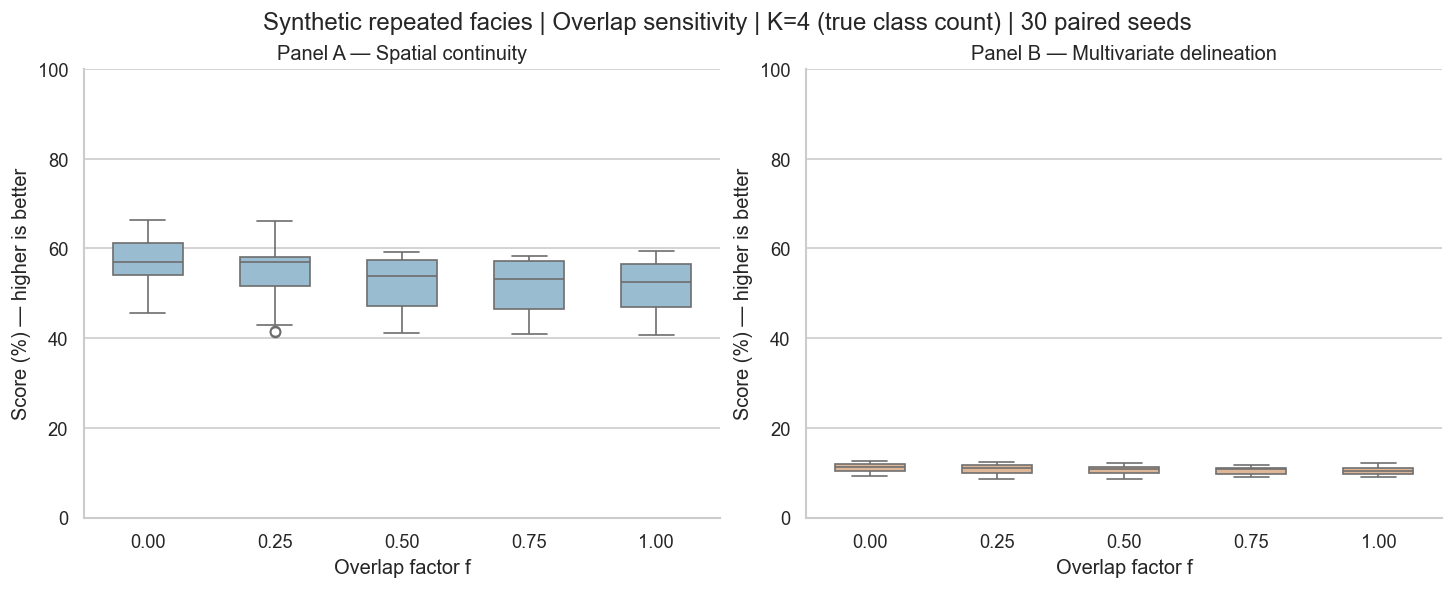

spatial                         multivariate                       
          count  median     min     max        count  median    min     max
value K                                                                    
0.00  4      30  57.079  45.659  66.249           30  11.174  9.185  12.563
0.25  4      30  56.989  41.293  66.136           30  11.051  8.613  12.317
0.50  4      30  53.953  41.116  59.220           30  10.718  8.660  12.160
0.75  4      30  53.090  40.903  58.315           30  10.713  8.945  11.765
1.00  4      30  52.539  40.711  59.358           30  10.426  8.961  12.130

In [4]:
overlap_results = run_experiment('overlap', OVERLAP_VALUES)
plot_experiment(overlap_results, OVERLAP_VALUES, 'Overlap sensitivity', 'Overlap factor f')

## Ramp-duration experiment

Sweep **0, 10, 25, 50, 100 iterations** via `phase3_ramp_iterations`, holding `overlap_sc_factor=0.5`, and `c_sc=10` fixed. Zero applies the automatic target share immediately at the start of Phase 3 (no gradual ramp). Positive durations linearly increase the scheduled share from zero to the target; 25 is the default. The total optimization schedule remains (100, 100, 250) iterations. The same 30 seeds are used as in the overlap experiment.

ramp: completed seed 1/30
ramp: completed seed 2/30
ramp: completed seed 3/30
ramp: completed seed 4/30
ramp: completed seed 5/30
ramp: completed seed 6/30
ramp: completed seed 7/30
ramp: completed seed 8/30
ramp: completed seed 9/30
ramp: completed seed 10/30
ramp: completed seed 11/30
ramp: completed seed 12/30
ramp: completed seed 13/30
ramp: completed seed 14/30
ramp: completed seed 15/30
ramp: completed seed 16/30
ramp: completed seed 17/30
ramp: completed seed 18/30
ramp: completed seed 19/30
ramp: completed seed 20/30
ramp: completed seed 21/30
ramp: completed seed 22/30
ramp: completed seed 23/30
ramp: completed seed 24/30
ramp: completed seed 25/30
ramp: completed seed 26/30
ramp: completed seed 27/30
ramp: completed seed 28/30
ramp: completed seed 29/30
ramp: completed seed 30/30


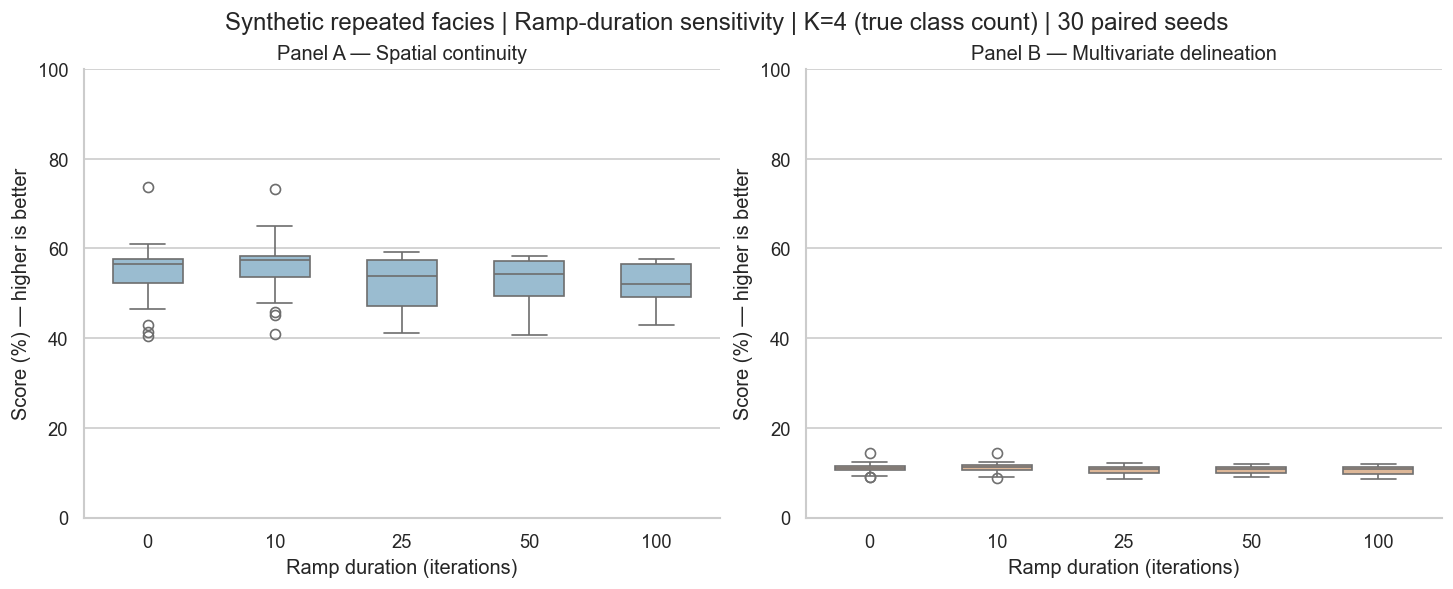

spatial                         multivariate                       
          count  median     min     max        count  median    min     max
value K                                                                    
0.0   4      30  56.477  40.569  73.650           30  11.016  8.999  14.492
10.0  4      30  57.349  40.993  73.203           30  11.312  8.706  14.416
25.0  4      30  53.953  41.116  59.220           30  10.718  8.660  12.160
50.0  4      30  54.197  40.723  58.359           30  10.792  8.946  11.906
100.0 4      30  52.120  42.968  57.636           30  10.754  8.573  11.839

In [5]:
ramp_results = run_experiment('ramp', RAMP_VALUES)
plot_experiment(ramp_results, RAMP_VALUES, 'Ramp-duration sensitivity', 'Ramp duration (iterations)')

## Diagnostics and complete results

In [6]:
sensitivity_results = pd.concat([overlap_results, ramp_results], ignore_index=True)
display(sensitivity_results.drop_duplicates(['experiment', 'value', 'seed'])
        .groupby(['experiment', 'value'])[['automatic_lambda', 'target_share', 'overlap_fraction']]
        .agg(['min', 'median', 'max']).round(5))
print(f'{len(sensitivity_results)} evaluation rows; {len(run_cache)} distinct SC-PaCMAP fits')

automatic_lambda                   target_share           \
                               min   median      max          min   median   
experiment value                                                             
overlap    0.00            0.12737  0.12737  0.12737      0.16445  0.16734   
           0.25            0.12737  0.12737  0.12737      0.16140  0.16427   
           0.50            0.12737  0.12737  0.12737      0.15870  0.16155   
           0.75            0.12737  0.12737  0.12737      0.15627  0.15911   
           1.00            0.12737  0.12737  0.12737      0.15409  0.15692   
ramp       0.00            0.12737  0.12737  0.12737      0.15870  0.16155   
           10.00           0.12737  0.12737  0.12737      0.15870  0.16155   
           25.00           0.12737  0.12737  0.12737      0.15870  0.16155   
           50.00           0.12737  0.12737  0.12737      0.15870  0.16155   
           100.00          0.12737  0.12737  0.12737      0.15870  0.16155   

                           overlap_fraction                  
                       max              min  median     max  
experiment value                                             
overlap    0.00    0.18390           0.1748  0.1748  0.1748  
           0.25    0.18027           0.1748  0.1748  0.1748  
           0.50    0.17705           0.1748  0.1748  0.1748  
           0.75    0.17416           0.1748  0.1748  0.1748  
           1.00    0.17156           0.1748  0.1748  0.1748  
ramp       0.00    0.17705           0.1748  0.1748  0.1748  
           10.00   0.17705           0.1748  0.1748  0.1748  
           25.00   0.17705           0.1748  0.1748  0.1748  
           50.00   0.17705           0.1748  0.1748  0.1748  
           100.00  0.17705           0.1748  0.1748  0.1748

300 evaluation rows; 270 distinct SC-PaCMAP fits
